# 🎮 Projet 02 : Mission "Microgrid & Bilan Énergétique"

Bienvenue dans le second projet de ta formation ! Tu es promu **Ingénieur Data & Microgrid**. Ta mission est d'analyser les données de production et de consommation d'un réseau électrique intelligent (panneaux solaires, batteries, réseau urbain) et de calculer son empreinte carbone.

---

## 💡 L'Écosystème du Projet : Fonctions & Pandas

Dans ce projet, nous allons franchir deux étapes cruciales du développeur IoT :
1. **Les Fonctions (`def`)** : Pour éviter de dupliquer les équations physiques ($P = U \times I$, $E = P \cdot t$).
2. **Pandas & DataFrames** : La bibliothèque standard industrielle pour manipuler des tableaux de séries temporelles complexes.

![Architecture Microgrid](images/microgrid_architecture.png)

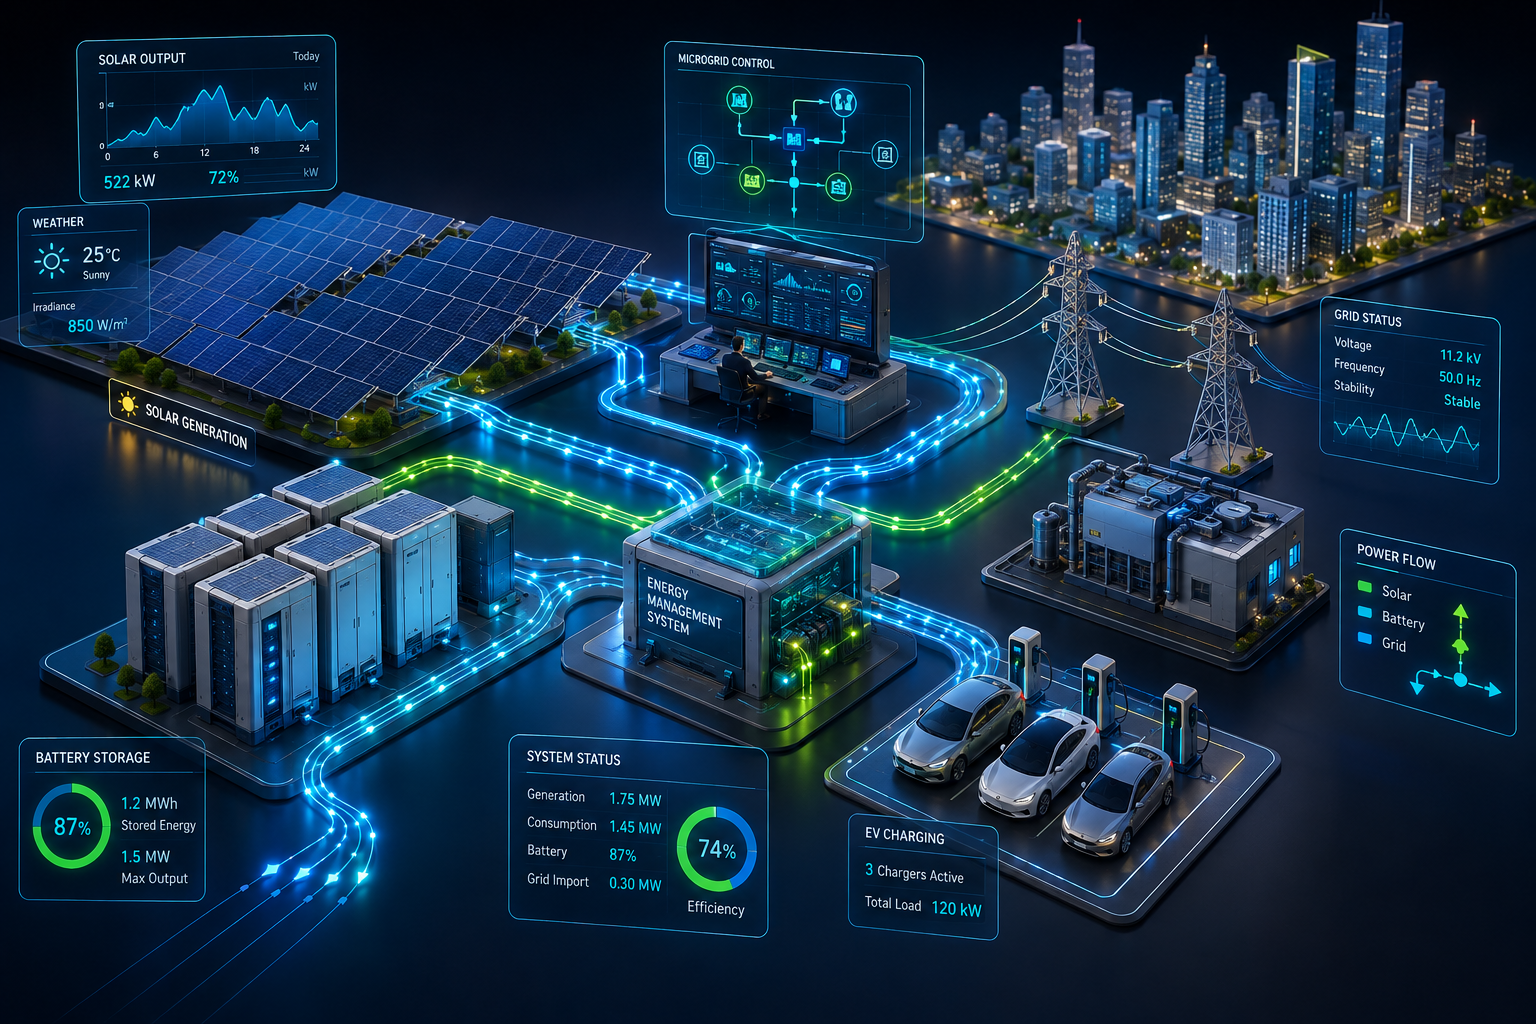

#### Nouvel bibliothèque à installer pandans

dans bash taper

`uv add pandas`

## 🟢 Niveau 1 : Modularité & Formules Physiques (Les Fonctions `def`)

### 📚 Cours théorique pas-à-pas :

#### 1. C'est quoi une Fonction (`def`) et Pourquoi l'utiliser ?
Jusqu'à présent, nous écrivions nos calculs au milieu du code. Mais si nous devons calculer la puissance de 50 capteurs différents, recopier la formule 50 fois crée du code lourd et propice aux erreurs.
Une **fonction** est une **usine à calculs réutilisable**. On lui donne des entrées (**paramètres**), elle fait le traitement, et renvoie un résultat (**`return`**).

```python
def nom_de_la_fonction(parametre1, parametre2):
    resultat = parametre1 + parametre2
    return resultat  # On fait sortir la valeur calculée

#### 2. Formules Physiques de Base en Électrotechnique

1. Puissance électrique ($P$) :
 $$P = U \times I \quad \text{(en Watts, W)}$$
 avec $U$ en Volts (V) et $I$ en Ampères (A). 

2. Énergie produite ou consommée ($E$) :$$E = \frac{P \times t}{1000} \quad \text{(en KiloWatt-heures, kWh)}$$
avec $P$ en Watts (W) et $t$ en Heures (h). Division par $1000$ pour passer de $\text{Wh}$ à $\text{kWh}$.

In [ ]:
# ==========================================
# QUÊTE 1 : Moteur de Calcul Physique (Fonctions)
# ==========================================
# Consignes :
# 1. Crée une fonction `calculer_puissance(tension, courant)` qui renvoie P = U * I.
# 2. Crée une fonction `calculer_energie_kwh(puissance_w, duree_h)` qui renvoie E = (P * t) / 1000.

# ### START CODE HERE ###

# ### END CODE HERE ###

# --- VALIDATION AUTOMATIQUE ---
p_test = calculer_puissance(230.0, 10.0)
e_test = calculer_energie_kwh(2300.0, 2.5)

assert p_test == 2300.0, f"Erreur Puissance : attendu 2300.0, obtenu {p_test}"
assert e_test == 5.75, f"Erreur Énergie : attendu 5.75, obtenu {e_test}"
print("🏆 Quête 1 réussie ! Fonctions physiques opérationnelles.")

# --- AFFICHAGE VISUEL EN TEMPS RÉEL ---
from utils import afficher_bilan_puissance
afficher_bilan_puissance(p_test, e_test)

## 🟡 Niveau 2 : Découverte de Pandas (Series & DataFrames)

### 📚 Cours théorique pas-à-pas :

#### 1. C'est quoi Pandas et qu'est-ce qu'un `DataFrame` ?
Un **DataFrame Pandas** est une table de données bidimensionnelle munie :
* De **noms de colonnes** (ex: `'tension_v'`, `'courant_a'`).
* D'un **Index** (les numéros de lignes ou des horodateurs/dates).

C'est l'équivalent d'une feuille Excel ultra-rapide et programmable directement en Python.

#### 2. Création et manipulation d'un DataFrame
On peut créer un DataFrame à partir d'un dictionnaire Python :
```python
import pandas as pd

donnees = {
    'tension_v': [220.0, 222.1, 219.5],
    'courant_a': [5.0, 5.2, 4.8]
}
df = pd.DataFrame(donnees)

#### 3. Créer une nouvelle colonne calculée (Vectorisation)
Avec Pandas, pas besoin de boucle for ! Si on multiplie deux colonnes, Pandas fait le calcul ligne par ligne automatiquement :

```python
df['puissance_w'] = df['tension_v'] * df['courant_a']

In [ ]:
import pandas as pd

# ==========================================
# QUÊTE 2 : Traitement de Logs IoT avec Pandas
# ==========================================
logs_iot = {
    'tension_v': [230.0, 228.5, 231.2, 229.0, 230.5],
    'courant_a': [12.0, 15.0, 18.5, 10.0, 14.0]
}

# ### START CODE HERE ###

# ### END CODE HERE ###

# --- VALIDATION AUTOMATIQUE ---
assert isinstance(df_solaire, pd.DataFrame), "df_solaire doit être un DataFrame Pandas"
assert 'puissance_kw' in df_solaire.columns, "La colonne puissance_kw est manquante"
assert round(df_solaire['puissance_kw'].sum(), 3) == 15.982, "Erreur sur les calculs de puissance"
print("🏆 Quête 2 réussie ! DataFrame initialisé avec succès.")

# --- AFFICHAGE VISUEL EN TEMPS RÉEL ---
from utils import tracer_dataframe_energie
tracer_dataframe_energie(df_solaire)

## 🟠 Niveau 3 : Nettoyage Temporel (Valeurs Manquantes `NaN` & Imputation)

### 📚 Cours théorique pas-à-pas :

#### 1. Les Trous de Données (`NaN` / Not a Number)
Lorsque le réseau IoT perd la connexion, Pandas insère un marqueur de donnée manquante appelé **`NaN`**.
Si on essaie de faire des moyennes ou des sommes avec des `NaN`, les résultats peuvent être altérés ou renvoyer `NaN`.

#### 2. Comment réparer une Série Temporelle ?
En physique et en capteurs, si un capteur ne répond pas à l'instant $t$, la meilleure estimation de sa valeur est la dernière valeur mesurée connue ($t-1$).
C'est la technique du **Forward Fill (`ffill`)** :

```python
# Remplace chaque NaN par la valeur valide précédente
df['colonne'] = df['colonne'].ffill()

#### 3. Conversion d'Horodateur (pd.to_datetime)
Pour que Pandas comprenne les dates sous forme de texte (ex: "2026-08-24 10:00"), on les convertit en format temporel réceptif :

```python
df['horodateur'] = pd.to_datetime(df['horodateur'])

In [ ]:
import numpy as np
import pandas as pd

# ==========================================
# QUÊTE 3 : Imputation de Pertes de Signal IoT
# ==========================================
releves_incomplets = {
    'horodateur': ['2026-08-24 08:00', '2026-08-24 09:00', '2026-08-24 10:00', '2026-08-24 11:00', '2026-08-24 12:00'],
    'tension_v': [230.0, np.nan, 228.0, np.nan, 232.0],  # Trous de tension !
    'courant_a': [10.0, 12.0, 15.0, 11.0, 14.0]
}


# Consignes :
# 1. Crée une copie du dataframe : `df_propre = df_brut.copy()`
# 2. Convertis la colonne 'horodateur' en datetime avec `pd.to_datetime()`.
# 3. Corrige la colonne 'tension_v' en utilisant l'imputation `.ffill()`.
# 4. Recalcule la colonne `energie_kwh` pour chaque intervalle de 1h : (tension_v * courant_a * 1h) / 1000.0.


df_brut = pd.DataFrame(releves_incomplets)

# ### START CODE HERE ###

# ### END CODE HERE ###

# --- VALIDATION AUTOMATIQUE ---
assert df_propre['tension_v'].isna().sum() == 0, "Il reste encore des valeurs NaN !"
assert df_propre.loc[1, 'tension_v'] == 230.0, "Erreur sur le premier FFill"
assert round(df_propre['energie_kwh'].sum(), 3) == 14.236, "Erreur sur le total d'énergie"
print("🏆 Quête 3 réussie ! Série temporelle réparée.")

# --- AFFICHAGE VISUEL EN TEMPS RÉEL ---
from utils import tracer_nettoyage_pandas
tracer_nettoyage_pandas(df_brut, df_propre)

## 🔴 Niveau 4 : Agrégation & Bilan par Jour (`.groupby()`)

### 📚 Cours théorique pas-à-pas :

#### 1. Le Concept du Split-Apply-Combine (`.groupby()`)
Pour calculer la production d'énergie jour par jour ou site par site, on utilise la méthode **`.groupby()`**.
Elle réalise 3 opérations en une seule commande :
1. **Split** : Découpe la table selon les catégories (ex: par jour ou par capteur).
2. **Apply** : Applique un calcul sur chaque groupe (`.sum()`, `.mean()`, `.max()`).
3. **Combine** : Fusionne les résultats dans un nouveau DataFrame propre.

```python
# Exemple : Somme de l'énergie par jour
df_quotidien = df.groupby('date')['energie_kwh'].sum().reset_index()

In [ ]:
# ==========================================
# QUÊTE 4 : Agrégation de la Production Quotidienne
# ==========================================
donnees_semaine = {
    'date': ['2026-08-24', '2026-08-24', '2026-08-25', '2026-08-25', '2026-08-26', '2026-08-26'],
    'capteur_id': ['SOLAR_01', 'SOLAR_02', 'SOLAR_01', 'SOLAR_02', 'SOLAR_01', 'SOLAR_02'],
    'energie_kwh': [12.5, 14.0, 15.2, 16.8, 11.0, 10.5]
}

df_production = pd.DataFrame(donnees_semaine)

# Consignes :
# 1. Utilise `.groupby('date')` sur `df_production` pour calculer la somme d'énergie par date.
# 2. Stocke le résultat dans un DataFrame `df_journalier` et ajoute `.reset_index()`.

# ### START CODE HERE ###

# ### END CODE HERE ###

# --- VALIDATION AUTOMATIQUE ---
assert isinstance(df_journalier, pd.DataFrame), "df_journalier doit être un DataFrame"
assert len(df_journalier) == 3, "Il doit y avoir exactement 3 jours consolidés"
assert df_journalier.loc[df_journalier['date'] == '2026-08-25', 'energie_kwh'].values[0] == 32.0, "Erreur agrégation"
print("🏆 Quête 4 réussie ! Bilan quotidien validé.")

# --- AFFICHAGE VISUEL EN TEMPS RÉEL ---
from utils import tracer_agrégation_journaliere
tracer_agrégation_journaliere(df_journalier)

## 🟣 Niveau 5 : Filtrage Avancé & Empreinte Carbone

### 📚 Cours théorique pas-à-pas :

#### 1. Le Filtrage Booléen dans Pandas
Pour extraire les lignes d'un DataFrame qui respectent un critère de surconsommation, on applique un **masque booléen** :
```python
# Extrait uniquement les lignes où la puissance dépasse 3.0 kW
df_surchauffe = df[df['puissance_kw'] > 3.0]

#### 2. Calcul du Bilan CO2L'intensité carbone de l'électricité dépend de la source.
Si l'électricité vient du réseau pendant les heures de pointe, son facteur d'émission est de $0.450 \text{ kg CO}_2 / \text{kWh}$.L'impact carbone total est :$$\text{Émissions CO}_2 (\text{kg}) = \text{Énergie Total (kWh)} \times \text{Facteur CO}_2$$

In [ ]:
# ==========================================
# QUÊTE 5 : Détection des Pics & Impact Carbone
# ==========================================
logs_reseau = {
    'horodateur': ['12:00', '13:00', '14:00', '15:00', '16:00', '17:00'],
    'puissance_kw': [2.1, 4.5, 5.2, 1.8, 4.8, 2.0]
}

df_reseau = pd.DataFrame(logs_reseau)
seuil_critique_kw = 4.0
facteur_co2_kg_kwh = 0.450  # 450g de CO2 par kWh

# Consignes :
# 1. Filtre `df_reseau` pour ne garder que les lignes où `puissance_kw` >= seuil_critique_kw.
#    Stocke le résultat dans `df_pics`.
# 2. Calcule la somme de la puissance de ces pics dans `energie_pics_kwh` (en supposant des créneaux de 1h).
# 3. Calcule l'empreinte carbone totale de ces pics `total_co2_kg` = energie_pics_kwh * facteur_co2_kg_kwh.

# ### START CODE HERE ###

# ### END CODE HERE ###

# --- VALIDATION AUTOMATIQUE ---
assert len(df_pics) == 3, f"Nombre de pics incorrect : attendu 3, obtenu {len(df_pics)}"
assert round(energie_pics_kwh, 2) == 14.5, f"Énergie pics incorrecte : {energie_pics_kwh}"
assert round(total_co2_kg, 3) == 6.525, f"Total CO2 incorrect : {total_co2_kg}"
print("🏆 Quête 5 réussie ! Empreinte carbone calculée.")

# --- AFFICHAGE VISUEL EN TEMPS RÉEL ---
from utils import tracer_emissions_co2
tracer_emissions_co2(df_pics, total_co2_kg)

## 👑 Bilan Final du Projet 02

Félicitations ! Tu as conçu un pipeline complet d'analyse de données temporelles :
1. Structuration du code par des **fonctions physiques**.
2. Manipulation de données vectorielles avec **Pandas**.
3. Réparation de signaux IoT avec **l'imputation temporelle `ffill`**.
4. Consolidation des bilans avec **`.groupby()`**.
5. Calcul d'impact écologique et détection d'anomalies de consommation.

In [ ]:
from utils import afficher_dashboard_iot

# Impression du bilan synthétique console final
afficher_dashboard_iot("MICROGRID_SMART_CITY_02", df_solaire[['puissance_kw']].values)